## Задание 4 Методы классификации (повышение эффективности их работы)

Датасет `powerconsumption.csv`: 52 416 наблюдений потребления энергии за 10-минутный интервал, тот же, что в работе 2.

- Datetime: интервал в десять минут
- Temperature: температура воздуха
- Humidity: влажность
- WindSpeed: скорость ветра
- GeneralDiffuseFlows, DiffuseFlows: рассеянная солнечная радиация
- PowerConsumption_Zone1/2/3: потребление по трём зонам города


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import StratifiedKFold

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.4})

In [2]:
df = pd.read_csv("powerconsumption.csv")
df['Datetime'] = pd.to_datetime(df['Datetime'], format = '%m/%d/%Y %H:%M')
df = df.set_index('Datetime').sort_index()

df_hour = df.resample('h').mean()
data = df_hour[['PowerConsumption_Zone1', 'Temperature', 'Humidity']].iloc[:3000]
print (data.shape)
data.head()

(3000, 3)


,PowerConsumption_Zone1,Temperature,Humidity
Datetime,,,
2017-01-01 00:00:00,29197.974683,6.196833,75.066667
2017-01-01 01:00:00,24657.215190,5.548833,77.583333
2017-01-01 02:00:00,22083.037973,5.054333,78.933333
2017-01-01 03:00:00,20811.139240,5.004333,77.083333
2017-01-01 04:00:00,20475.949367,5.097667,74.050000


In [3]:
lags = 24
y = data['PowerConsumption_Zone1']

X = pd.concat([y.shift(i).rename(f'lag{i}') for i in range(1, lags + 1)]
              + [data['Temperature'], data['Humidity']], axis = 1).dropna()
y = y.loc[X.index]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle = False)


In [4]:
prev = X['lag1']
cls = (prev < y).astype('int')

cls_train, cls_test = train_test_split(cls, test_size = 0.2, shuffle = False)

print(cls_train.mean())
print(cls_test.mean())


0.4432773109243697
0.46476510067114096


### Модели без кросс-валидации 

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


knn = make_pipeline(StandardScaler(), KNeighborsClassifier(9)).fit(x_train, cls_train)
svm = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble = False)).fit(x_train, cls_train)
logreg = make_pipeline(StandardScaler(), LogisticRegression()).fit(x_train, cls_train)

In [6]:
from sklearn.metrics import (accuracy_score, f1_score, log_loss, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

proba = {'kNN': knn.predict_proba(x_test)[:, 1],
         'SVM': svm.predict_proba(x_test)[:, 1],
         'LogReg': logreg.predict_proba(x_test)[:, 1],}

rows = {name: [
                accuracy_score(cls_test, p > 0.5), f1_score(cls_test, p > 0.5),    
                log_loss(cls_test, p), 
                roc_auc_score(cls_test, p)]
        for name, p in proba.items()}

cls_metrics = pd.DataFrame(rows, index = ['Accuracy', 'F1', 'LogLoss', 'ROC-AUC']).T.round(3)
cls_metrics


,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.854,0.835,1.095,0.925
SVM,0.849,0.828,0.320,0.946
LogReg,0.857,0.832,0.300,0.949


### Модели с кросс-валидацией 

In [7]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import auc


tscv = TimeSeriesSplit(n_splits=5)

kNN_metrics = []
SVM_metrics = []
LogReg_metrics = []

oof_knn = np.full(len(x_train), np.nan)
oof_svm = np.full(len(x_train), np.nan)
oof_lr = np.full(len(x_train), np.nan)




for tr_idx, tst_idx in tscv.split(x_train): 
        knn_cv = make_pipeline(StandardScaler(), KNeighborsClassifier(9)).fit(x_train.iloc[tr_idx], cls_train.iloc[tr_idx])
        svm_cv = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble = False)).fit(x_train.iloc[tr_idx], cls_train.iloc[tr_idx])
        logreg_cv = make_pipeline(StandardScaler(), LogisticRegression()).fit(x_train.iloc[tr_idx], cls_train.iloc[tr_idx])

        p = knn_cv.predict_proba(x_train.iloc[tst_idx])[:, 1]
        oof_knn[tst_idx] = p
        y_true = cls_train.iloc[tst_idx]

        kNN_metrics.append([accuracy_score(y_true, p > 0.5), 
                        f1_score(y_true, p > 0.5),    
                        log_loss(y_true, p), 
                        roc_auc_score(y_true, p)])

        p = svm_cv.predict_proba(x_train.iloc[tst_idx])[:, 1]
        oof_svm[tst_idx] = p
        y_true = cls_train.iloc[tst_idx]
        
        SVM_metrics.append([accuracy_score(y_true, p > 0.5), 
                        f1_score(y_true, p > 0.5),    
                        log_loss(y_true, p), 
                        roc_auc_score(y_true, p)])

        p = logreg_cv.predict_proba(x_train.iloc[tst_idx])[:, 1]
        oof_lr[tst_idx] = p
        y_true = cls_train.iloc[tst_idx]
        
        
        LogReg_metrics.append([accuracy_score(y_true, p > 0.5), 
                        f1_score(y_true, p > 0.5),    
                        log_loss(y_true, p), 
                        roc_auc_score(y_true, p)])

mask = ~np.isnan(oof_knn)

mean_knn = np.array(kNN_metrics).mean(axis = 0)
std_knn = np.array(kNN_metrics).std(axis = 0)

mean_svm = np.array(SVM_metrics).mean(axis = 0)
std_svm = np.array(SVM_metrics).std(axis = 0)

mean_lr = np.array(LogReg_metrics).mean(axis = 0)
std_lr = np.array(LogReg_metrics).std(axis = 0)

cv_mean = {'kNN': mean_knn, 'SVM': mean_svm, 'LogReg': mean_lr} 
cv_mean_metrics = pd.DataFrame(cv_mean, index = ['Accuracy', 'F1', 'LogLoss', 'ROC-AUC']).T.round(3)

cv_std = {'kNN': std_knn, 'SVM': std_svm, 'LogReg': std_lr} 
cv_std_metrics = pd.DataFrame(cv_std, index = ['Accuracy', 'F1', 'LogLoss', 'ROC-AUC']).T.round(3)


display(cv_mean_metrics, cv_std_metrics)



,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.872,0.853,1.086,0.938
SVM,0.857,0.842,0.337,0.937
LogReg,0.852,0.830,0.319,0.938


,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.020,0.026,0.394,0.013
SVM,0.015,0.022,0.022,0.007
LogReg,0.026,0.031,0.034,0.015


In [8]:
result = pd.concat(
                [cls_metrics, cv_mean_metrics, cv_std_metrics], 
                axis = 0, 
                keys = ['hold-out', 'CV среднее', 'CV std']
                ).swaplevel().reindex(['kNN', 'SVM', 'LogReg'], level = 0)
result

Accuracy     F1  LogLoss  ROC-AUC
kNN    hold-out       0.854  0.835    1.095    0.925
       CV среднее     0.872  0.853    1.086    0.938
       CV std         0.020  0.026    0.394    0.013
SVM    hold-out       0.849  0.828    0.320    0.946
       CV среднее     0.857  0.842    0.337    0.937
       CV std         0.015  0.022    0.022    0.007
LogReg hold-out       0.857  0.832    0.300    0.949
       CV среднее     0.852  0.830    0.319    0.938
       CV std         0.026  0.031    0.034    0.015

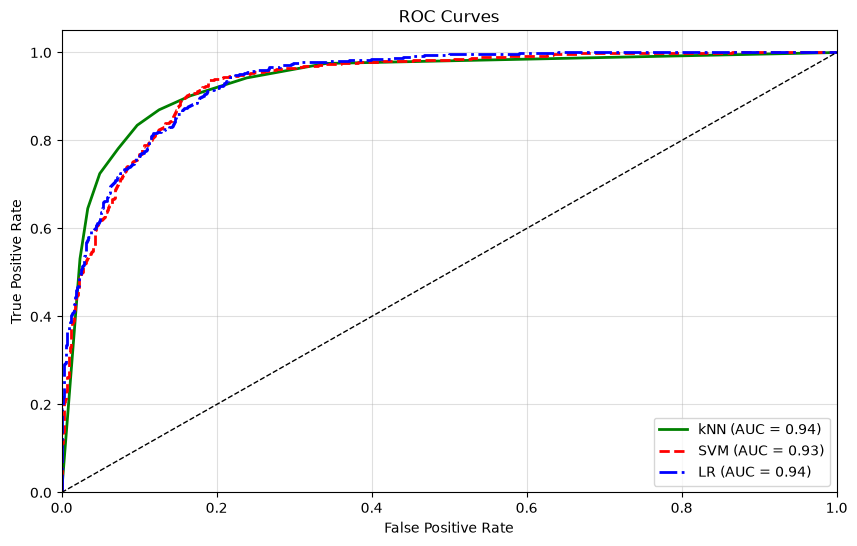

In [9]:
y_probs = {'kNN': oof_knn[mask], 'SVM': oof_svm[mask], 'LR': oof_lr[mask]}

plt.figure(figsize=(10, 6))
colors = {'kNN': 'green', 'SVM': 'red', 'LR': 'blue'}
linestyles = {'kNN': '-', 'SVM': '--', 'LR': '-.'}

for name, prob in y_probs.items():
    fpr, tpr, thresholds = roc_curve(cls_train[mask], prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[name], linestyle=linestyles[name],
             linewidth=2, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1) # случайный классификатор
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


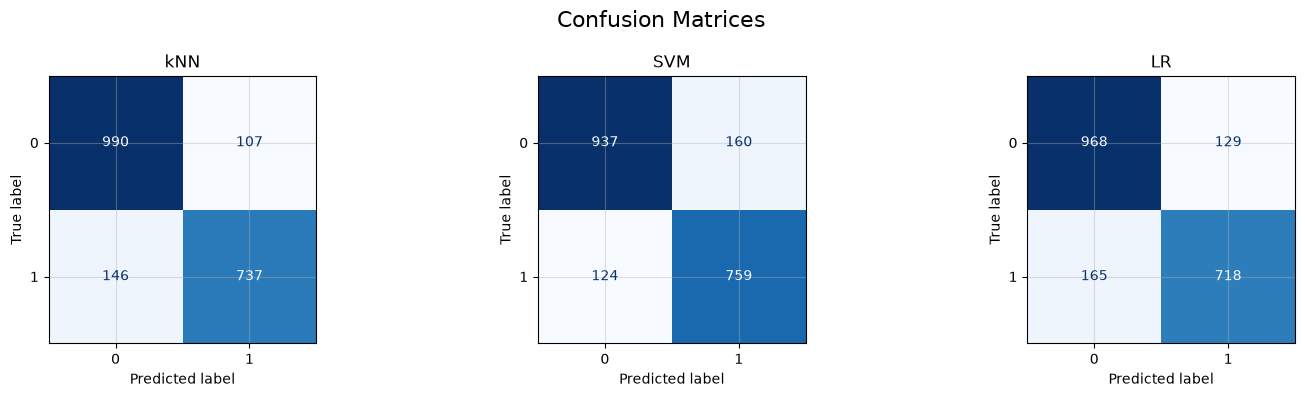

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_preds = {'kNN': (oof_knn[mask] > 0.5).astype(int),
           'SVM': (oof_svm[mask] > 0.5).astype(int),
           'LR':  (oof_lr[mask]  > 0.5).astype(int)}

# Визуализация матриц ошибок
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Confusion Matrices', fontsize=16)

for idx, (name, y_pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(cls_train[mask], y_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f'{name}')

plt.tight_layout()
plt.show()

На кросс-валидации все три модели дают Accuracy 0.85–0.87 и ROC-AUC около 0.94. Результаты hold-out из прошлой работы отличаются от среднего по CV не больше чем на 0.02, так что та оценка была устойчивой. kNN лучший по Accuracy и F1, но его LogLoss около 1.09 хуже случайного угадывания (0.693): модель слишком уверена в ошибочных ответах. У SVM и LogReg LogLoss 0.32–0.34, их вероятностям можно доверять больше.

### Композиция моделей

In [11]:
from sklearn.ensemble import VotingClassifier

voting_hard = VotingClassifier(
    estimators=[('knn', knn), ('svm', svm), ('lr', logreg)],
    voting='hard'
    )

voting_soft = VotingClassifier(
    estimators = [('knn', knn), ('svm', svm), ('lr', logreg)],
    voting='soft'
)

voting_hard.fit(x_train, cls_train)
voting_soft.fit(x_train, cls_train)

y_pred_hard = voting_hard.predict(x_test)
y_pred_soft = voting_soft.predict(x_test)
y_pred_soft_proba = voting_soft.predict_proba(x_test)[:, 1]

comp_result = pd.DataFrame()

comp_result['hard_voting'] = {
        'Accuracy': accuracy_score(cls_test, y_pred_hard),
        'F1': f1_score(cls_test, y_pred_hard),
        'LogLoss': np.nan,
        'ROC-AUC': np.nan
}

comp_result['soft_voting'] = {
        'Accuracy': accuracy_score(cls_test, y_pred_soft),
        'F1': f1_score(cls_test, y_pred_soft),
        'LogLoss': log_loss(cls_test, y_pred_soft_proba),
        'ROC-AUC': roc_auc_score(cls_test, y_pred_soft_proba)
}

pd.DataFrame(comp_result).T.round(4)

,Accuracy,F1,LogLoss,ROC-AUC
hard_voting,0.8674,0.8478,NaN,NaN
soft_voting,0.8591,0.8372,0.2857,0.9523


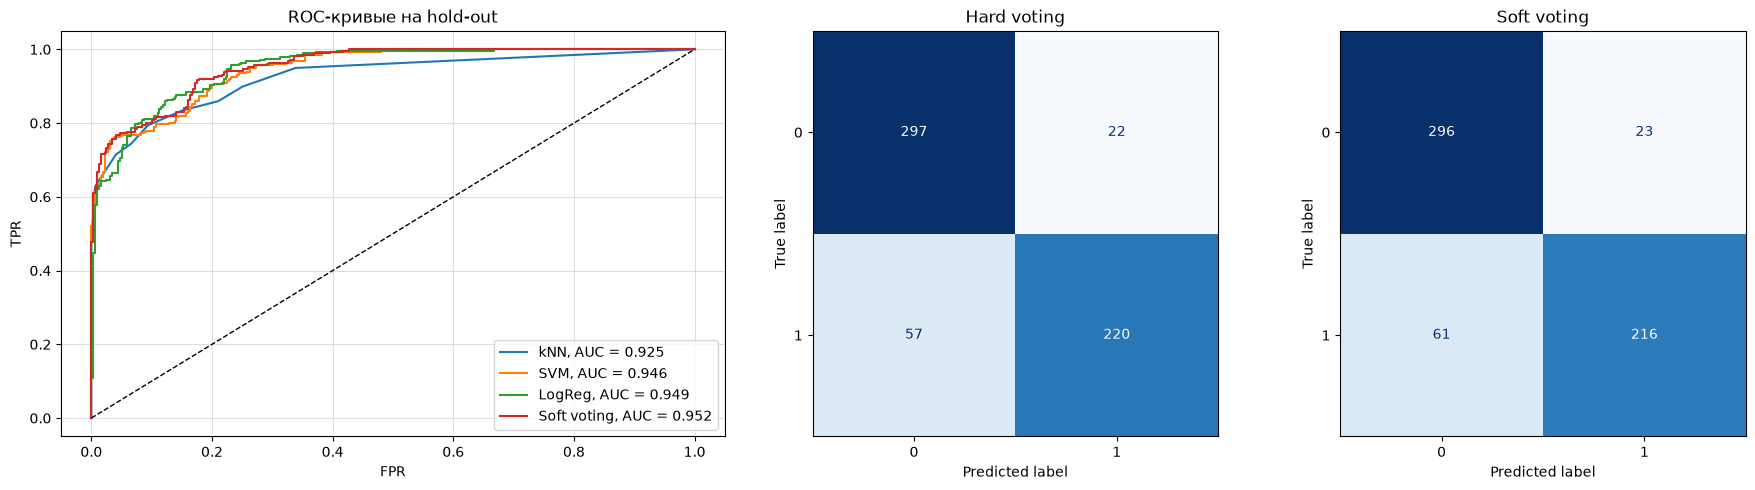

In [12]:
fpr_tpr = {'kNN': proba['kNN'], 'SVM': proba['SVM'], 'LogReg': proba['LogReg'],
           'Soft voting': y_pred_soft_proba}

fig, axes = plt.subplots(1, 3, figsize = (18, 5), gridspec_kw = {'width_ratios': [1.4, 1, 1]})

for name, p in fpr_tpr.items():
    fpr, tpr, _ = roc_curve(cls_test, p)
    axes[0].plot(fpr, tpr, label = f'{name}, AUC = {roc_auc_score(cls_test, p):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth = 1)
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('ROC-кривые на hold-out')
axes[0].legend(loc = 'lower right')

for ax, (name, pred) in zip(axes[1:], {'Hard voting': y_pred_hard, 'Soft voting': y_pred_soft}.items()):
    ConfusionMatrixDisplay(confusion_matrix(cls_test, pred)).plot(ax = ax, cmap = 'Blues', colorbar = False)
    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()

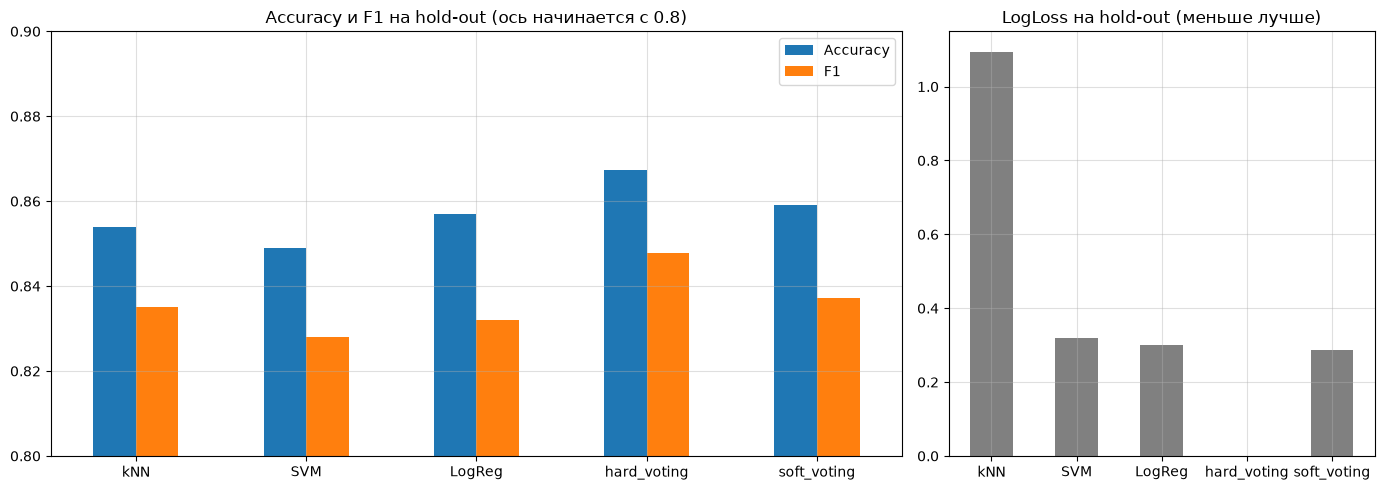

In [13]:
all_res = pd.concat([cls_metrics, comp_result.T])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})

all_res[['Accuracy', 'F1']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_ylim(0.8, 0.9)
axes[0].set_title('Accuracy и F1 на hold-out (ось начинается с 0.8)')
axes[0].grid(axis='y', alpha=0.4)

all_res['LogLoss'].plot(kind='bar', ax=axes[1], rot=0, color='gray')
axes[1].set_title('LogLoss на hold-out (меньше лучше)')
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

Hard voting дал лучшие Accuracy и F1 (0.867 и 0.848), выше любой одиночной модели. Soft voting немного уступает по Accuracy, зато у него лучшие LogLoss (0.286) и ROC-AUC (0.952): усреднение вероятностей гасит самоуверенность kNN. Матрицы ошибок почти совпадают, обе композиции чаще пропускают рост потребления (57–61 FN), чем ложно его предсказывают (22–23 FP).

### AdaBoost (Adaptive Boosting)

In [14]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier


dt = DecisionTreeClassifier(max_depth=1)

adaboost = AdaBoostClassifier(estimator=dt, n_estimators=50, learning_rate=1.0)

adaboost.fit(x_train, cls_train)

y_pred = adaboost.predict(x_test)
y_pred_proba = adaboost.predict_proba(x_test)

ada_result = pd.DataFrame()

ada_result['Adaboost'] = {
        'Accuracy': accuracy_score(cls_test, y_pred),
        'F1': f1_score(cls_test, y_pred),
        'LogLoss': log_loss(cls_test, y_pred_proba[:, 1]),
        'ROC-AUC': roc_auc_score(cls_test, y_pred_proba[:, 1])
}


pd.DataFrame(ada_result).T.round(4)


,Accuracy,F1,LogLoss,ROC-AUC
Adaboost,0.8423,0.822,0.5242,0.931


,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.854,0.835,1.095,0.925
SVM,0.849,0.828,0.320,0.946
LogReg,0.857,0.832,0.300,0.949
hard_voting,0.867,0.848,NaN,NaN
soft_voting,0.859,0.837,0.286,0.952
Adaboost,0.842,0.822,0.524,0.931


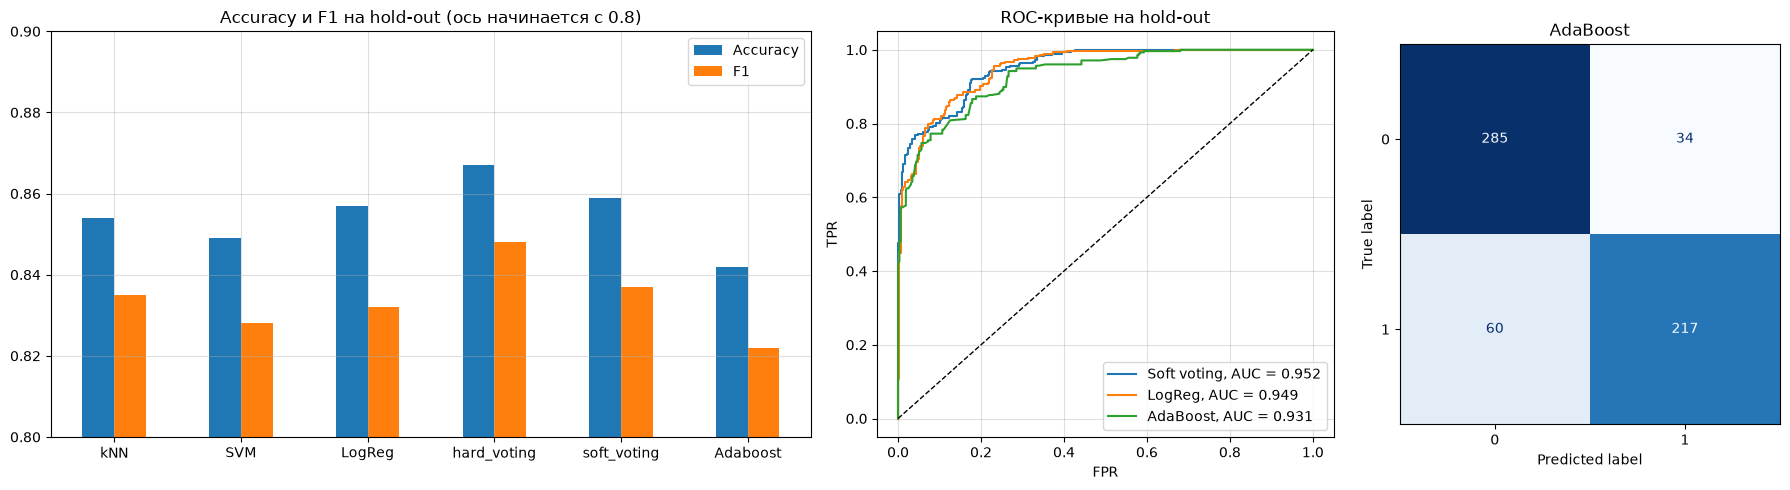

In [15]:
all_res = pd.concat([cls_metrics, comp_result.T, ada_result.T]).round(3)
display(all_res)

fig, axes = plt.subplots(1, 3, figsize = (18, 5), gridspec_kw = {'width_ratios': [2, 1.2, 1]})

all_res[['Accuracy', 'F1']].plot(kind = 'bar', ax = axes[0], rot = 0)
axes[0].set_ylim(0.8, 0.9)
axes[0].set_title('Accuracy и F1 на hold-out (ось начинается с 0.8)')

for name, p in {'Soft voting': y_pred_soft_proba, 'LogReg': proba['LogReg'],
                'AdaBoost': y_pred_proba[:, 1]}.items():
    fpr, tpr, _ = roc_curve(cls_test, p)
    axes[1].plot(fpr, tpr, label = f'{name}, AUC = {roc_auc_score(cls_test, p):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth = 1)
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].set_title('ROC-кривые на hold-out')
axes[1].legend(loc = 'lower right')

ConfusionMatrixDisplay(confusion_matrix(cls_test, y_pred)).plot(ax = axes[2], cmap = 'Blues', colorbar = False)
axes[2].set_title('AdaBoost')
axes[2].grid(False)

plt.tight_layout()
plt.show()

AdaBoost хуже всех по Accuracy и F1 (0.842 и 0.822), по ROC-AUC (0.931) он обходит только kNN. Ложных срабатываний у него больше, чем у голосования: 34 FP против 22–23. Лучший результат по совокупности метрик у soft voting, по доле верных ответов у hard voting.